# 10 - The Dynamic Workflow Engine: a Glass Box

**Part B - Petrophys Curriculum**

The dynamic workflow is the headline capability of `petrophys`: hand it a raw
well and it *inspects what curves are present*, decides which petrophysical
modules can run, chooses a method for each one, and executes the whole
interpretation pipeline in the correct order:

> QC -> Volume of clay -> Porosity -> Lithology -> Rw -> Water saturation ->
> Permeability -> Rock quality -> Net pay

The important word is **dynamic**. Nothing is hard-coded to a fixed curve list.
If a well has no resistivity, the Rw/Sw steps are skipped rather than crashing;
if only a density log is present, porosity falls back to a density-only route.

This notebook treats the engine as a **glass box**. We do not just read the
final answer - we read the *step trace*: which steps executed, which were
skipped, the method chosen per step and *why*, and the exact parameters used.
Then we prove it is steerable by overriding the saturation model and cutoffs
and measuring the difference in net pay.

## Learning goals

- Run `run_dynamic_workflow` on a real well and read `DynamicWorkflowResult`.
- Understand how the engine **auto-detects** available input curves and selects
  a method per module.
- Inspect the **step trace**: executed vs skipped steps, method, inputs,
  outputs, parameters, and human-readable decisions.
- Plot resulting curves (VCL, PHIE, SW) against the raw logs.
- Demonstrate **parameter overrides** - swap the Sw model and cutoffs and
  measure the change in computed net pay.
- Run a **zoned-by-formation** interpretation and summarise pay per formation.

### Prerequisites

Familiarity with the individual modules (clay volume, porosity, saturation,
net pay) from Part A helps, but this notebook is self-contained.

## Why this matters

A manual petrophysical interpretation is a long chain of decisions: *which*
clay indicator, *which* porosity route given the logs you have, *which*
saturation equation for this shaliness, *what* cutoffs for net pay. Each choice
depends on the previous one and on the curves actually available in the file.

The dynamic workflow encodes that decision chain once and makes it auditable.
The step trace is what turns an opaque "the model says 42 m of pay" into a
defensible interpretation you can hand to a reviewer.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.qaqc.standardization import standardize_curves
from petrophys.workflow import (
    run_dynamic_workflow,
    DynamicWorkflowConfig,
    DynamicWorkflowResult,
    run_dynamic_workflow_with_zones,
)
from petrophys.data import DATA_DIR

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("petrophys", petrophys.__version__)
print("DynamicWorkflowConfig ->", DynamicWorkflowConfig.__name__)
print("DynamicWorkflowResult ->", DynamicWorkflowResult.__name__)

petrophys 0.1.0
DynamicWorkflowConfig -> DynamicWorkflowConfig
DynamicWorkflowResult -> DynamicWorkflowResult


## 1. Load a well and see what the engine has to work with

We use **30/6-5**, a North Sea clastic well with a rich curve set. We
`standardize_curves` first so mnemonics are normalised to the names the
workflow looks for (`GR`, `RHOB`, `NPHI`, `RDEP`, ...). Standardisation mutates
the well in place, so we always reload a fresh copy when we need a clean start.

In [2]:
def load_well():
    """Return a fresh, standardized copy of 30/6-5."""
    w = read_las(petrophys.sample("30_6-5"))
    return standardize_curves(w, rename_curves=True, convert_units=True)

well = load_well()

# header.field on this well has mojibake; sanitize before printing ASCII.
field = (well.header.field or "").encode("ascii", "replace").decode("ascii")
print("Well          :", well.name)
print("Field         :", field)
print("Depth range   : %.1f - %.1f %s" % (well.start_depth, well.stop_depth, well.depth_unit))
print("Samples       :", well.n_samples)
print("Curves (%d)   :" % well.n_curves)
print("  " + ", ".join(sorted(well.curves)))

Well          : 30/6-5
Field         : OSEBERG ??ST
Depth range   : 176.6 - 3556.1 m
Samples       : 22176
Curves (20)   :
  BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, KV_CORE, LITHOLOGY_GEOLINK, NPHI, PEF, PHIC, RDEP, RHOB, RMED, RSHA, SOC, SP, SWC


### What can the engine detect?

The engine scans for a fixed vocabulary of input mnemonics. Below we reproduce
that detection so you can see, *before* running anything, which raw inputs are
present. These drive the `_can_*` gate on each module.

In [3]:
# The curve families the engine probes for (from DynamicWorkflow._detect_available_curves)
probe = ["GR", "SP", "NPHI", "RHOB", "DTC", "DTS", "RDEP", "RT",
         "RSHA", "RXO", "PEF", "CALI", "BS", "DRHO",
         "PHIC", "KH_CORE", "SWC", "SOC"]
present = [name for name in probe if well.has_curve(name)]
missing = [name for name in probe if not well.has_curve(name)]
print("Detected inputs :", ", ".join(present))
print("Not present     :", ", ".join(missing))
print()
print("Interpretation:")
print("  - GR present            -> clay volume can run")
print("  - RHOB + NPHI + PEF     -> porosity + multi-mineral lithology can run")
print("  - RDEP present          -> Rw / Sw / invasion can run")
print("  - PHIC/KH_CORE present  -> log-vs-core correction can run")

Detected inputs : GR, SP, NPHI, RHOB, DTC, RDEP, RSHA, PEF, CALI, BS, DRHO, PHIC, KH_CORE, SWC, SOC
Not present     : DTS, RT, RXO

Interpretation:
  - GR present            -> clay volume can run
  - RHOB + NPHI + PEF     -> porosity + multi-mineral lithology can run
  - RDEP present          -> Rw / Sw / invasion can run
  - PHIC/KH_CORE present  -> log-vs-core correction can run


## 2. Configure the run

`DynamicWorkflowConfig` is a dataclass of *optional* parameters. Anything left
`None` is auto-detected or defaulted. 30/6-5 has **no** salinity / BHT / Rmf /
Rw stored in its header, so we must supply the environmental parameters
ourselves and flag them as assumptions.

The values below are reasonable North-Sea assumptions for a teaching run - in a
real study they would come from the mud report, a DST, or an offset well.

In [4]:
ASSUMED = DynamicWorkflowConfig(
    # --- environmental assumptions (NOT in the LAS header) ---
    bht_f=210.0,            # assumed bottom-hole temperature
    td_ft=11700.0,          # ~3566 m total depth in feet
    rw=0.03,                # assumed formation-water resistivity
    rw_meas_temp_f=210.0,
    salinity_ppm=30000.0,
    rmf_at_meas_temp=0.05,  # assumed mud-filtrate resistivity
    # --- interpretation choices ---
    lithology="clastic",
    matrix_type="sandstone",
    sw_model="auto",        # let the router pick per-depth
    # --- net-pay cutoffs ---
    vcl_cutoff=0.4,
    sw_cutoff=0.6,
    phie_cutoff=0.08,
)
print("Assumed environmental inputs (flag these in any report):")
for k in ["bht_f", "td_ft", "rw", "salinity_ppm", "rmf_at_meas_temp"]:
    print("  %-16s = %s" % (k, getattr(ASSUMED, k)))
print("Cutoffs: vcl<=%.2f  sw<=%.2f  phie>=%.2f"
      % (ASSUMED.vcl_cutoff, ASSUMED.sw_cutoff, ASSUMED.phie_cutoff))

Assumed environmental inputs (flag these in any report):
  bht_f            = 210.0
  td_ft            = 11700.0
  rw               = 0.03
  salinity_ppm     = 30000.0
  rmf_at_meas_temp = 0.05
Cutoffs: vcl<=0.40  sw<=0.60  phie>=0.08


## 3. Run the pipeline

`run_dynamic_workflow(well, config=...)` mutates the well in place (adding
computed curves such as `VCL`, `PHIE`, `SW`, `PERM`, `NET_PAY`) and returns a
`DynamicWorkflowResult` carrying the full trace.

In [5]:
well = load_well()                       # fresh copy
result = run_dynamic_workflow(well, config=ASSUMED)

print("Overall success :", result.success)
print("Steps executed  :", len(result.steps_executed))
print("Steps skipped   :", len(result.steps_skipped))
print()
print("Executed :", ", ".join(s.step for s in result.steps_executed))
print("Skipped  :", ", ".join(result.steps_skipped) or "none")

Overall success : True
Steps executed  : 16
Steps skipped   : 2

Executed : temperature, bad_hole, vclay, rcl, rmf, porosity, lithology, core_correction, rw, invasion, saturation, permeability, rock_quality, bvw, mhi, net_pay
Skipped  : hc_correction, porosity_refinement


### Why were those steps skipped?

Skipping is a *feature*, not a failure. A step is skipped when its `_can_*`
gate is not satisfied by the available curves/parameters.

- `hc_correction` - only runs when `apply_hc_correction=True` (we left it off).
- `porosity_refinement` - needs a per-depth lithology curve written by a
  vendor log; here lithology is solved but not written as a refinement input.

The engine records *specific* per-step skip reasons too.

In [6]:
if result.specific_steps_skipped:
    for step, reason in result.specific_steps_skipped.items():
        print("%-22s -> %s" % (step, reason))
else:
    print("No step raised a specific skip reason.")
print()
# Computed scalars/curves the workflow surfaced on the result object
def _rng(v):
    a = np.asarray(v, dtype=float); a = a[np.isfinite(a)]
    if a.size == 0: return "n/a"
    if a.size == 1: return "%.4f" % a[0]
    return "%.4f - %.4f" % (a.min(), a.max())
print("Rw computed  :", _rng(result.rw_computed), "ohm.m")
print("Rmf computed :", _rng(result.rmf_computed), "ohm.m")

No step raised a specific skip reason.

Rw computed  : 0.0301 - 0.0795 ohm.m
Rmf computed : 0.0189 - 0.0500 ohm.m


## 4. The glass box: the step trace table

This is the heart of the notebook. `result.to_dataframe()` renders one row per
executed step with the **method chosen**, the **input curves consumed**, the
**output curves written**, and the **decisions** taken. Read it top to bottom -
it is the audit trail of the interpretation.

In [7]:
trace = result.to_dataframe()
# Compact view: what ran and how.
with pd.option_context("display.max_colwidth", 46):
    print(trace[["Step", "Status", "Method", "Input Curves", "Output Curves"]].to_string(index=False))

           Step Status                                      Method                      Input Curves                                                 Output Curves
    temperature     OK                    linear_gradient_from_BHT                                                                                            TEMP
       bad_hole     OK                          caliper_drho_flags         CALI, BS, DRHO, RHOB, PEF                                                      BAD_HOLE
          vclay     OK                                      linear                GR, SP, NPHI, RHOB       VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_ND, VCLND
            rcl     OK                   lithology_shale_median_rt                         RDEP, VCL                                                              
            rmf     OK         arps_temperature_profile_correction                                                                                             RMF
       porosity     OK

### Zooming in on a single step's reasoning

Each `StepResult` also carries free-text `decisions` - the branch logic the
module took. Let's inspect the **saturation** step, which is where the method
routing is most interesting.

In [8]:
sat = next(s for s in result.steps_executed if s.step == "saturation")
print("Step       :", sat.step)
print("Method     :", sat.method)
print("Inputs     :", ", ".join(sat.input_curves))
print("Outputs    :", ", ".join(sat.output_curves))
print("Parameters :")
for k, v in sat.parameters.items():
    print("   %-18s %s" % (k, ("%.4g" % v) if isinstance(v, float) else v))
print("Decisions  :")
for d in sat.decisions:
    print("   -> " + d)

Step       : saturation
Method     : archie+simandoux+dual_water
Inputs     : RDEP, PHIE_CC, VCL
Outputs    : SW, SXO
Parameters :
   sw_model           archie+simandoux+dual_water
   sw_model_requested auto
   sw_model_sample_counts {'archie': 9363, 'simandoux': 11123, 'dual_water': 1690}
   a                  lithology_dependent
   m                  2
   n                  2
   archie_coefficients {'SANDSTONE': {'a': np.float64(0.81), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'granular_sandstone', 'samples': 12904}, 'SILT': {'a': np.float64(1.0), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'fine_clastic', 'samples': 6006}, 'IGNEOUS': {'a': np.float64(1.0), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'non_archie_special_lithology', 'samples': 264}, 'LIMESTONE': {'a': np.float64(1.0), 'm': np.float64(2.0), 'n': np.float64(2.0), 'closest_lithology': 'clean_carbonate', 'samples': 1783}, 'SHALE': {'a': np.float64(1.0), 'm':

The method string `archie+simandoux+dual_water` tells you the router did not
pick one global equation - it chose **per depth** based on shaliness: clean sand
gets Archie, shaly intervals get Simandoux / dual-water. That per-depth routing
is exactly what a manual interpreter does by hand.

## 5. Plot the resulting curves

A glass box should let you *see* the outputs, not just tabulate them. Below we
overlay the raw triple-combo inputs with two headline computed curves - volume
of clay (`VCL`) and effective porosity (`PHIE`) - plus the net-pay flag.
We restrict to the Brent/Statfjord reservoir section for clarity.

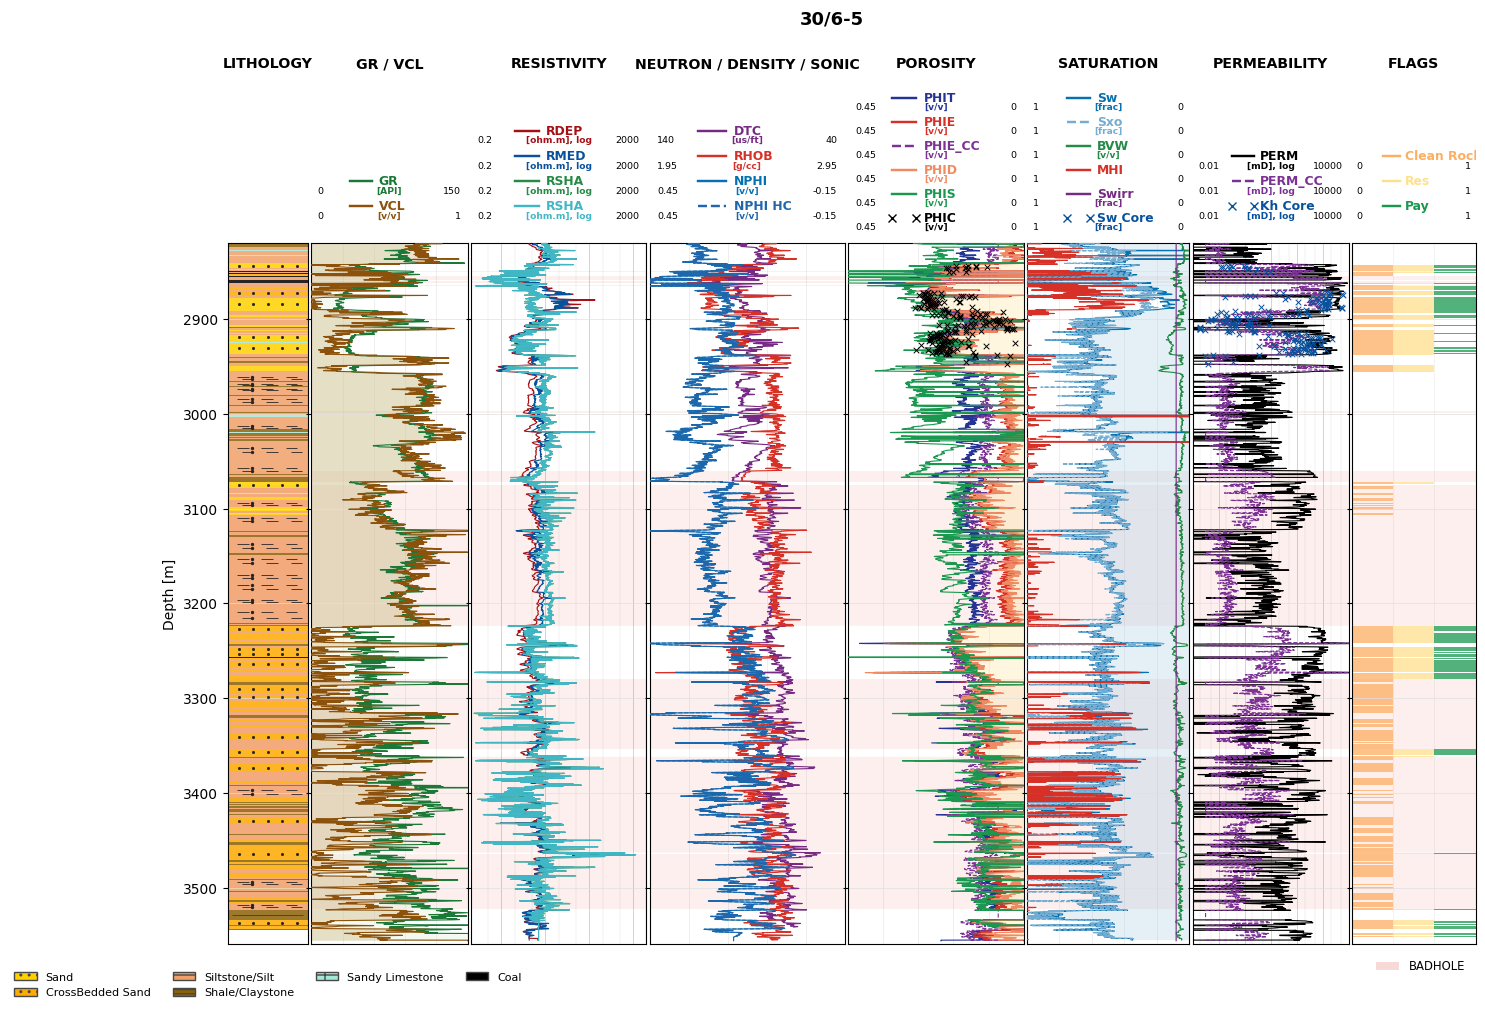

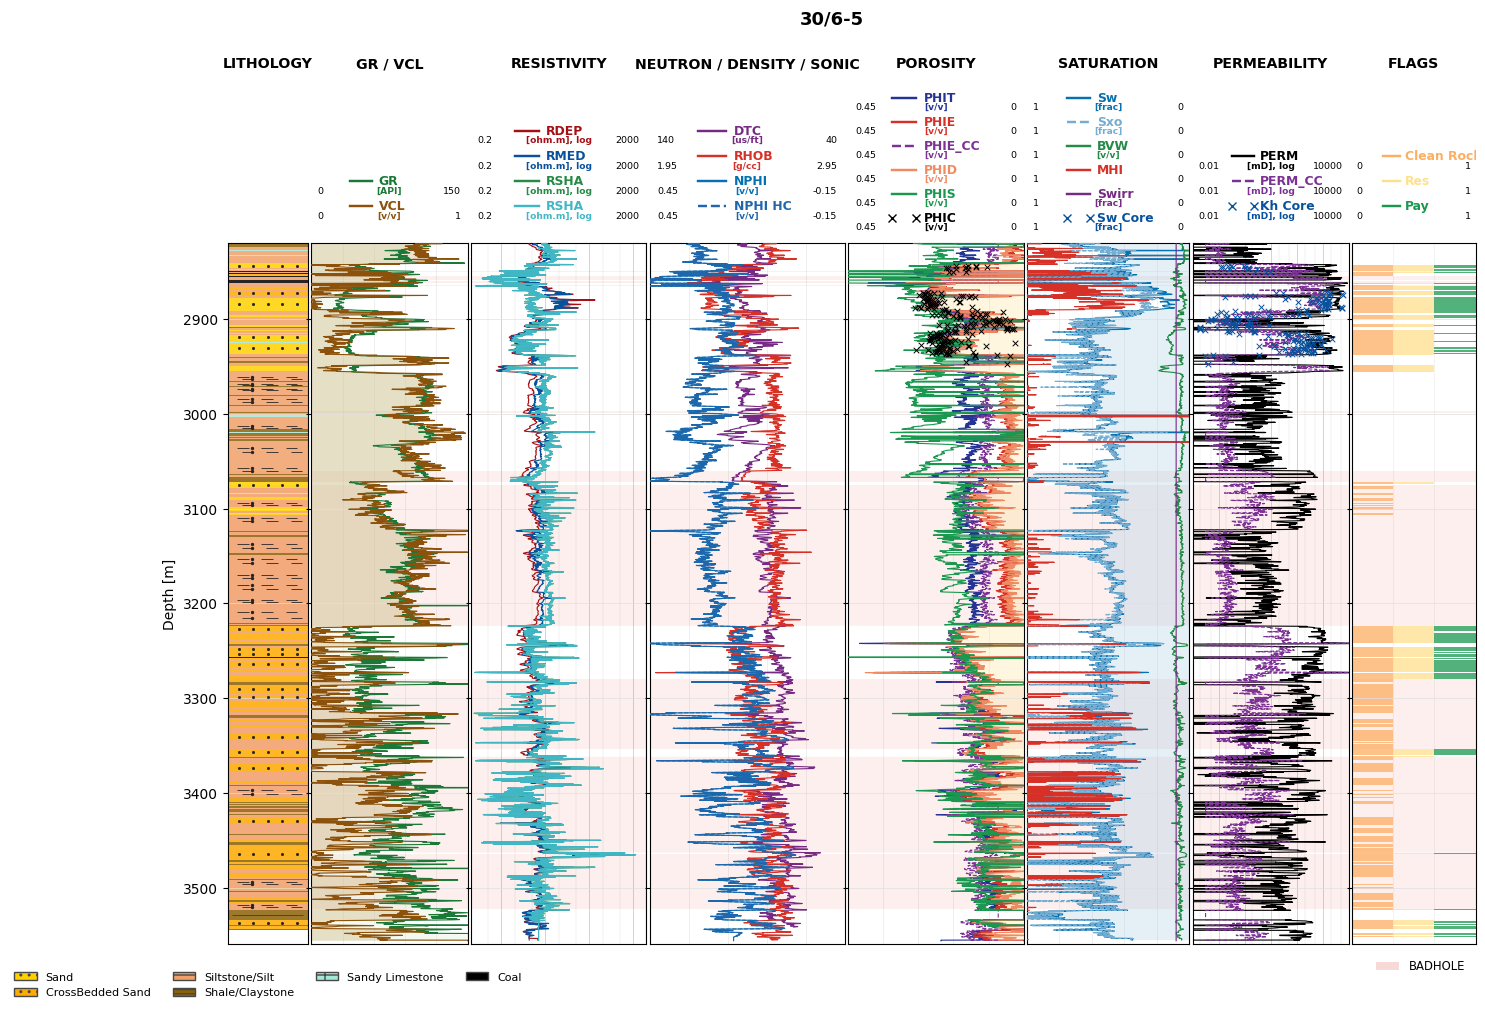

In [9]:
from petrophys.visualization import create_log_viewer

top, bot = 2820.0, 3560.0            # reservoir section (Brent down to Statfjord)

# The library's template-driven log viewer renders GR/VCL, density/neutron,
# PHIE and the NET_PAY flag track directly from the well's own curves. The
# "petrophysics" template resolves the standard aliases and auto-renders the
# net-rock/net-res/net-pay flag track and lithology band.
viewer = create_log_viewer(
    well,
    template_defaults="petrophysics",
    depth_range=(top, bot),
    figsize=(13, 10),
)
viewer.fig

The clay volume climbs in the shales (high GR), effective porosity opens up in
the clean sands, and the net-pay flag lights up only where porosity is high,
clay is low, and water saturation is below cutoff - exactly the intersection of
the three cutoffs we configured.

## 6. Parameter overrides - proving the box is steerable

The same engine, re-run with a different **saturation model** and a tighter
**Sw cutoff**, should move the answer. We keep every other assumption fixed and
compare net pay. Because the workflow mutates the well, we reload a fresh copy
for each run.

In [10]:
def total_net_pay(w):
    """Net-pay thickness = flagged samples x median depth step."""
    c = w.get("NET_PAY")
    if c is None:
        return 0.0
    step = float(np.nanmedian(np.abs(np.diff(w.depth))))
    return float(np.nansum(c.data > 0.5) * step)

# Run A: Simandoux, sw_cutoff = 0.6 (our base assumptions)
wA = load_well()
rA = run_dynamic_workflow(wA, config=DynamicWorkflowConfig(
    bht_f=210, td_ft=11700, rw=0.03, rw_meas_temp_f=210, salinity_ppm=30000,
    rmf_at_meas_temp=0.05, lithology="clastic", matrix_type="sandstone",
    sw_model="simandoux", vcl_cutoff=0.4, sw_cutoff=0.6, phie_cutoff=0.08))

# Run B: Archie, tighter sw_cutoff = 0.5
wB = load_well()
rB = run_dynamic_workflow(wB, config=DynamicWorkflowConfig(
    bht_f=210, td_ft=11700, rw=0.03, rw_meas_temp_f=210, salinity_ppm=30000,
    rmf_at_meas_temp=0.05, lithology="clastic", matrix_type="sandstone",
    sw_model="archie", vcl_cutoff=0.4, sw_cutoff=0.5, phie_cutoff=0.08))

methA = next(s for s in rA.steps_executed if s.step == "saturation").method
methB = next(s for s in rB.steps_executed if s.step == "saturation").method
print("Run A: Sw model 'simandoux', cutoff 0.60 -> method %-20s net pay = %6.1f m"
      % (methA, total_net_pay(wA)))
print("Run B: Sw model 'archie',    cutoff 0.50 -> method %-20s net pay = %6.1f m"
      % (methB, total_net_pay(wB)))
print()
print("Delta net pay (A - B) = %.1f m" % (total_net_pay(wA) - total_net_pay(wB)))

Run A: Sw model 'simandoux', cutoff 0.60 -> method simandoux            net pay =  395.2 m
Run B: Sw model 'archie',    cutoff 0.50 -> method archie               net pay =  116.7 m

Delta net pay (A - B) = 278.5 m


### Reading the diff

Forcing `sw_model` overrides the per-depth router: run A uses Simandoux
everywhere, run B uses Archie everywhere. Combined with a tighter Sw cutoff,
run B is a much more conservative interpretation and flags substantially less
pay. Neither is "correct" in the abstract - the point is that the engine makes
the sensitivity **explicit and reproducible**: change one documented knob, see
the effect, keep the trace.

Let's compare the two `SW` curves directly over the reservoir.

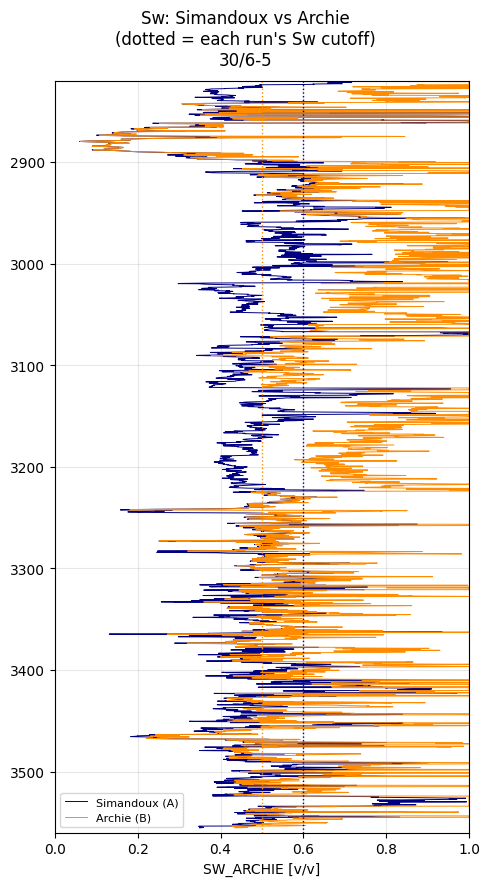

In [11]:
from petrophys.visualization import LogPlot

# LogPlot binds a single well, so attach both SW arrays onto wA as distinctly
# named curves (wA and wB are fresh loads of the same well -> identical depth
# grids, so the arrays align to wA.depth).
wA.add_curve("SW_SIMANDOUX", wA.get("SW").data, unit="v/v",
             description="Sw from run A (Simandoux)")
wA.add_curve("SW_ARCHIE", wB.get("SW").data, unit="v/v",
             description="Sw from run B (Archie)")

lp = LogPlot(wA, figsize=(5, 9))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "SW_SIMANDOUX", color="navy", linewidth=0.7,
             label="Simandoux (A)", xlim=(0, 1))
lp.add_curve(0, "SW_ARCHIE", color="darkorange", linewidth=0.7,
             label="Archie (B)")
lp.set_depth_range(top=2820, bottom=3560)

# Minor styling on the library-returned axis: each run's Sw cutoff as a vline.
ax = lp.axes[0]
ax.axvline(0.6, color="navy", ls=":", lw=1)
ax.axvline(0.5, color="darkorange", ls=":", lw=1)
ax.legend(loc="lower left", fontsize=8)

lp.add_title("Sw: Simandoux vs Archie\n(dotted = each run's Sw cutoff)")
lp.show()

## 7. Zoned-by-formation interpretation

Real wells rarely use one set of parameters top to bottom. The `petrophys`
formation tops for 30/6-5 live in `formations_30_6-5.csv`. The engine exposes
`run_dynamic_workflow_with_zones`, which reads *zoned* parameters
(`RW_Z1`, `RW_Z2`, ...) from the LAS header and applies per-interval overrides
automatically.

30/6-5's LAS carries **no** zoned parameters, so that helper runs the base
interpretation but finds zero explicit zones - let's confirm that, then do the
practical thing: run once, and *summarise per formation* using the tops CSV.

In [12]:
wz = load_well()
zres = run_dynamic_workflow_with_zones(wz, DynamicWorkflowConfig(
    bht_f=210, td_ft=11700, rw=0.03, rw_meas_temp_f=210, salinity_ppm=30000,
    rmf_at_meas_temp=0.05, lithology="clastic", matrix_type="sandstone"))
print("Zoned helper ran. Base success:", zres.base_result.success)
print("Explicit LAS-defined zones found:", len(zres.zones))
print("(30/6-5 has no RW_Zn / M_Zn header parameters, so per-zone overrides = none.)")
print("Warnings:", zres.warnings or "none")

Zoned helper ran. Base success: True
Explicit LAS-defined zones found: 0
(30/6-5 has no RW_Zn / M_Zn header parameters, so per-zone overrides = none.)
Warnings: none


### Summarising the single interpretation per formation

`FormationTops` + `IntervalAnalyzer` compute per-formation net pay / NTG /
averages from the curves the workflow just wrote. This is the "zoned view" that
matters for reporting. (Notebook 11 covers formation analysis in depth; here it
closes the loop on the dynamic workflow.)

In [13]:
from petrophys.formation import FormationTops, IntervalAnalyzer

tops = FormationTops.from_csv(str(DATA_DIR / "formations_30_6-5.csv"))
print("Loaded %d formation intervals (overlaps present: %s -" % (len(tops), tops.has_overlaps()),
      "groups + sub-formations, expected).")

analyzer = IntervalAnalyzer(wz)                        # wz has computed curves
summaries = analyzer.analyze_all(tops.clip_to_well(wz))
fdf = IntervalAnalyzer.to_dataframe(summaries)

view = fdf[["Name", "Top", "Bottom", "Gross", "Net Pay", "NTG", "Avg PHIE", "Avg Sw"]].copy()
view = view[view["Net Pay"] > 0.1].round({"Top":0,"Bottom":0,"Gross":1,"Net Pay":1,
                                          "NTG":3,"Avg PHIE":3,"Avg Sw":3})
print("\nFormations carrying net pay:")
print(view.to_string(index=False))

Loaded 20 formation intervals (overlaps present: True - groups + sub-formations, expected).

Formations carrying net pay:
         Name    Top  Bottom  Gross  Net Pay   NTG  Avg PHIE  Avg Sw
HORDALAND GP.  879.0  1908.0 1029.0    296.0 0.288     0.401   0.551
 ROGALAND GP. 1908.0  2203.0  295.0      2.6 0.009     0.340   0.638
   Balder Fm. 1908.0  2023.0  115.1      0.3 0.003     0.279   0.688
     Sele Fm. 2023.0  2123.0  100.0      1.7 0.017     0.352   0.659
    Lista Fm. 2123.0  2203.0   80.0      0.6 0.008     0.337   0.554
 SHETLAND GP. 2203.0  2408.0  205.0      0.6 0.003     0.281   0.592
   VIKING GP. 2452.0  2841.0  388.9      0.8 0.002     0.254   0.464
  Heather Fm. 2593.0  2841.0  248.0      0.8 0.003     0.254   0.464
     BAAT GP. 2841.0  2958.0  117.0     64.5 0.551     0.191   0.408
     Ness Fm. 2841.0  2865.0   24.1      7.5 0.310     0.190   0.392
    Etive Fm. 2865.0  2958.0   93.0     57.0 0.613     0.192   0.410
Statfjord Fm. 3223.0  3556.0  333.0     68.0 0.204

## Pitfalls & parameter choices

- **Standardise first.** The engine looks for canonical mnemonics; run
  `standardize_curves` before the workflow or steps silently skip.
- **The workflow mutates the well.** Reload a fresh copy for every comparison
  run, or you will be interpreting already-processed curves.
- **Supply missing environmental inputs and flag them.** 30/6-5 has no
  BHT/Rw/salinity/Rmf in its header; every value we passed is an assumption and
  belongs in the "Data Limitations" section of any report.
- **Skipped != broken.** Check `steps_skipped` and `specific_steps_skipped`
  before trusting or debugging a run.
- **Forcing `sw_model` disables per-depth routing.** `sw_model="auto"` is
  usually what you want; force a single model only for sensitivity tests.
- **Zoned overrides need zoned LAS parameters.** `run_dynamic_workflow_with_zones`
  keys off `<PARAM>_Z1/_Z2` header entries; without them it reduces to the base
  run.

## Recap

- `run_dynamic_workflow` auto-detects inputs, selects a method per module, and
  runs the full QC -> Vcl -> porosity -> lithology -> Rw -> Sw -> permeability
  -> rock quality -> net pay pipeline.
- `DynamicWorkflowResult` is a **glass box**: `steps_executed`,
  `steps_skipped`, `specific_steps_skipped`, per-step `method` / `input_curves`
  / `output_curves` / `parameters` / `decisions`, and `to_dataframe()`.
- Overriding `sw_model` and cutoffs moves net pay in a documented, reproducible
  way - we saw the delta directly.
- The same computed well feeds per-formation summaries for reporting.

## Try it yourself

> **Exercise 1.** Re-run the workflow with `apply_hc_correction=True` and
> `hc_type="oil"`. Does `hc_correction` now appear in `steps_executed`? How does
> PHIE change in the gas/oil-bearing sands?
>
> **Exercise 2.** Set `phie_cutoff=0.12` (tighter porosity cutoff) and compare
> net pay per formation against the base run.
>
> **Exercise 3.** Export the full audit trail with
> `result.to_json("trace.json")` and open it - every routing decision is
> serialised.

## What's next

Continue with **11 - Formation & Interval Analysis**, which builds a
formation/zone hierarchy from the tops and per-interval lithology CSVs and
produces formation-level NTG / net-pay reporting with depth-track shading.